In [1]:
# ==========================================
# CricPredict AI
# Step 1: Install Required Libraries
# ==========================================

!pip install pandas numpy matplotlib seaborn scikit-learn plotly

In [2]:
# ==========================================
# Step 2: Import Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("CricPredict AI Started Successfully!")

CricPredict AI Started Successfully!


In [6]:
# ==========================================
# Step 3: Upload IPL Dataset
# ==========================================

from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully!")

Saving match_info.csv to match_info.csv
Saving ball_by_ball_ipl.csv to ball_by_ball_ipl.csv
Files uploaded successfully!


In [7]:
# ==========================================
# CricPredict AI
# Step 6: Load Uploaded IPL Datasets
# ==========================================

import pandas as pd

# Load your uploaded files
matches = pd.read_csv("match_info.csv")
deliveries = pd.read_csv("ball_by_ball_ipl.csv")

# Display dataset dimensions
print("MATCH DATASET")
print("Rows and columns:", matches.shape)

print("\nBALL-BY-BALL DATASET")
print("Rows and columns:", deliveries.shape)

print("\nBoth datasets loaded successfully!")

MATCH DATASET
Rows and columns: (11252, 45)

BALL-BY-BALL DATASET
Rows and columns: (295732, 32)

Both datasets loaded successfully!


In [8]:
# ==========================================
# Step 7: Dataset Exploration
# ==========================================

print("MATCH DATA COLUMNS:")
print(matches.columns.tolist())

print("\nBALL-BY-BALL DATA COLUMNS:")
print(deliveries.columns.tolist())

print("\nFIRST 5 MATCH RECORDS:")
display(matches.head())

print("\nFIRST 5 DELIVERY RECORDS:")
display(deliveries.head())

MATCH DATA COLUMNS:
['match_id', 'match_type', 'team1', 'team2', 'team1_icc_type', 'team2_icc_type', 'gender', 'season', 'start_date', 'venue', 'city', 'event', 'match_number', 'toss_winner', 'toss_decision', 'winner', 'winner_runs', 'winner_wickets', 'player_of_match1', 'umpire1', 'umpire2', 'tv_umpire1', 'reserve_umpire1', 'match_referee', 'outcome', 'method', 'eliminator', 'bowl_out', 'winner_innings', 'super_over', 'declared', 'overs', 'target_overs', 'target_runs', 'match_type_number', 'team_type', 'balls_per_over', 'toss_uncontested', 'player_of_match2', 'umpire3', 'umpire4', 'tv_umpire2', 'reserve_umpire2', 'end_date', 'match_dates']

BALL-BY-BALL DATA COLUMNS:
['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed', 'match_type', 'over_no', 'delive

,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,team_type,balls_per_over,toss_uncontested,player_of_match2,umpire3,umpire4,tv_umpire2,reserve_umpire2,end_date,match_dates
0,1478411,T20,Portugal,Norway,Associate,Associate,female,2025,2025-04-07,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-07,2025/04/07
1,1478412,T20,Portugal,Norway,Associate,Associate,female,2025,2025-04-08,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-08,2025/04/08
2,1478413,T20,Norway,Portugal,Associate,Associate,female,2025,2025-04-09,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-09,2025/04/09
3,1496587,T20,Sri Lanka,England,Full Member,Full Member,male,2026,2026-09-19,Old Trafford,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2026-09-19,2026/09/19
4,1528302,T20,Portugal,France,Associate,Associate,male,2026,2026-04-06,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2026-04-06,2026/04/06



FIRST 5 DELIVERY RECORDS:


,match_id,season,start_date,venue,innings,ball,batting_team,bowling_team,striker,non_striker,...,match_type,over_no,delivery_in_over,actual_delivery,non_boundary,fielder_1,fielder_2,fielder_3,gender,team_type
0,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,1,0.1,NaN,NaN,NaN,NaN,male,club
1,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,2,0.2,NaN,NaN,NaN,NaN,male,club
2,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,3,0.3,NaN,NaN,NaN,NaN,male,club
3,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,4,0.4,NaN,NaN,NaN,NaN,male,club
4,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,5,0.5,NaN,NaN,NaN,NaN,male,club


In [9]:
# ==========================================
# CricPredict AI
# Step 8: Complete Dataset Inspection
# ==========================================

print("========== MATCH DATASET ==========")

for col in matches.columns:
    print(col)

print("\n========== BALL-BY-BALL DATASET ==========")

for col in deliveries.columns:
    print(col)

print("\n========== DATASET DIMENSIONS ==========")

print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)

print("\n========== MATCH ID VALIDATION ==========")

match_ids = set(matches["match_id"].dropna())
delivery_ids = set(deliveries["match_id"].dropna())

print("Unique match IDs:", len(match_ids))
print("Unique delivery match IDs:", len(delivery_ids))

print("Common match IDs:", len(match_ids & delivery_ids))

print("\n========== MATCH DATA SAMPLE ==========")
display(matches.head(3))

print("\n========== DELIVERY DATA SAMPLE ==========")
display(deliveries.head(3))

========== MATCH DATASET ==========
match_id
match_type
team1
team2
team1_icc_type
team2_icc_type
gender
season
start_date
venue
city
event
match_number
toss_winner
toss_decision
winner
winner_runs
winner_wickets
player_of_match1
umpire1
umpire2
tv_umpire1
reserve_umpire1
match_referee
outcome
method
eliminator
bowl_out
winner_innings
super_over
declared
overs
target_overs
target_runs
match_type_number
team_type
balls_per_over
toss_uncontested
player_of_match2
umpire3
umpire4
tv_umpire2
reserve_umpire2
end_date
match_dates

========== BALL-BY-BALL DATASET ==========
match_id
season
start_date
venue
innings
ball
batting_team
bowling_team
striker
non_striker
bowler
runs_off_bat
extras
wides
noballs
byes
legbyes
penalty
wicket_type
player_dismissed
other_wicket_type
other_player_dismissed
match_type
over_no
delivery_in_over
actual_delivery
non_boundary
fielder_1
fielder_2
fielder_3
gender
team_type

========== DATASET DIMENSIONS ==========
Matches: (11252, 45)
Deliveries: (295732, 32)

==

,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,team_type,balls_per_over,toss_uncontested,player_of_match2,umpire3,umpire4,tv_umpire2,reserve_umpire2,end_date,match_dates
0,1478411,T20,Portugal,Norway,Associate,Associate,female,2025,2025-04-07,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-07,2025/04/07
1,1478412,T20,Portugal,Norway,Associate,Associate,female,2025,2025-04-08,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-08,2025/04/08
2,1478413,T20,Norway,Portugal,Associate,Associate,female,2025,2025-04-09,Santarem Cricket Ground,...,international,6,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-09,2025/04/09



========== DELIVERY DATA SAMPLE ==========


,match_id,season,start_date,venue,innings,ball,batting_team,bowling_team,striker,non_striker,...,match_type,over_no,delivery_in_over,actual_delivery,non_boundary,fielder_1,fielder_2,fielder_3,gender,team_type
0,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,1,0.1,NaN,NaN,NaN,NaN,male,club
1,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,2,0.2,NaN,NaN,NaN,NaN,male,club
2,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,3,0.3,NaN,NaN,NaN,NaN,male,club


In [10]:
# Check important match information

print("MATCH RESULT COLUMNS")

print(matches.filter(
    regex="winner|result|team|season|match_id"
).head())

print("\nDELIVERY RUNS AND WICKET COLUMNS")

print(deliveries.filter(
    regex="run|wicket|dismiss|bowler|striker|ball|innings"
).head())

MATCH RESULT COLUMNS
   match_id      team1     team2 team1_icc_type team2_icc_type season  \
0   1478411   Portugal    Norway      Associate      Associate   2025   
1   1478412   Portugal    Norway      Associate      Associate   2025   
2   1478413     Norway  Portugal      Associate      Associate   2025   
3   1496587  Sri Lanka   England    Full Member    Full Member   2026   
4   1528302   Portugal    France      Associate      Associate   2026   

  toss_winner    winner  winner_runs  winner_wickets  winner_innings  \
0    Portugal  Portugal         16.0             NaN             NaN   
1    Portugal    Norway          NaN             5.0             NaN   
2    Portugal  Portugal          NaN             9.0             NaN   
3     England   England          NaN             8.0             NaN   
4    Portugal  Portugal         28.0             NaN             NaN   

       team_type  
0  international  
1  international  
2  international  
3  international  
4  internati

In [11]:
# ==========================================
# CricPredict AI
# Step 10: Dataset Compatibility Check
# ==========================================

print("MATCH DATASET COLUMNS:")
print(matches.columns.tolist())

print("\nDELIVERY DATASET COLUMNS:")
print(deliveries.columns.tolist())

# Check common match IDs
match_ids = set(matches["match_id"].dropna())
delivery_ids = set(deliveries["match_id"].dropna())

common_ids = match_ids.intersection(delivery_ids)

print("\n========== MATCH ID CHECK ==========")

print("Total match IDs:", len(match_ids))
print("Total delivery match IDs:", len(delivery_ids))
print("Common match IDs:", len(common_ids))

print("\n========== MATCH TYPES ==========")

print(matches["match_type"].value_counts())

print("\n========== SEASONS ==========")

print(sorted(matches["season"].dropna().unique()))

print("\n========== COMMON MATCHES ==========")

display(
    matches[matches["match_id"].isin(common_ids)][
        ["match_id", "match_type", "team1", "team2",
         "season", "winner"]
    ].head(10)
)

MATCH DATASET COLUMNS:
['match_id', 'match_type', 'team1', 'team2', 'team1_icc_type', 'team2_icc_type', 'gender', 'season', 'start_date', 'venue', 'city', 'event', 'match_number', 'toss_winner', 'toss_decision', 'winner', 'winner_runs', 'winner_wickets', 'player_of_match1', 'umpire1', 'umpire2', 'tv_umpire1', 'reserve_umpire1', 'match_referee', 'outcome', 'method', 'eliminator', 'bowl_out', 'winner_innings', 'super_over', 'declared', 'overs', 'target_overs', 'target_runs', 'match_type_number', 'team_type', 'balls_per_over', 'toss_uncontested', 'player_of_match2', 'umpire3', 'umpire4', 'tv_umpire2', 'reserve_umpire2', 'end_date', 'match_dates']

DELIVERY DATASET COLUMNS:
['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed', 'match_type', 'over_no', 'deli

,match_id,match_type,team1,team2,season,winner
10009,1082591,IPL,Sunrisers Hyderabad,Royal Challengers Bangalore,2017,Sunrisers Hyderabad
10010,1082592,IPL,Rising Pune Supergiant,Mumbai Indians,2017,Rising Pune Supergiant
10011,1082593,IPL,Gujarat Lions,Kolkata Knight Riders,2017,Kolkata Knight Riders
10012,1082594,IPL,Kings XI Punjab,Rising Pune Supergiant,2017,Kings XI Punjab
10013,1082595,IPL,Royal Challengers Bangalore,Delhi Daredevils,2017,Royal Challengers Bangalore
10014,1082596,IPL,Sunrisers Hyderabad,Gujarat Lions,2017,Sunrisers Hyderabad
10015,1082597,IPL,Mumbai Indians,Kolkata Knight Riders,2017,Mumbai Indians
10016,1082598,IPL,Kings XI Punjab,Royal Challengers Bangalore,2017,Kings XI Punjab
10017,1082599,IPL,Rising Pune Supergiant,Delhi Daredevils,2017,Delhi Daredevils
10018,1082600,IPL,Mumbai Indians,Sunrisers Hyderabad,2017,Mumbai Indians


In [12]:
# ==========================================
# Step 11: Inspect Scoring Information
# ==========================================

print("RUN-RELATED COLUMNS:")

run_columns = [
    col for col in deliveries.columns
    if any(word in col.lower()
           for word in ["run", "wide", "bye", "penalty", "wicket"])
]

print(run_columns)

display(deliveries[run_columns].head(10))

RUN-RELATED COLUMNS:
['runs_off_bat', 'wides', 'byes', 'legbyes', 'penalty', 'wicket_type', 'other_wicket_type']


,runs_off_bat,wides,byes,legbyes,penalty,wicket_type,other_wicket_type
0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,0,NaN,NaN,NaN,NaN,NaN,NaN
2,4,NaN,NaN,NaN,NaN,NaN,NaN
3,0,NaN,NaN,NaN,NaN,NaN,NaN
4,0,2.0,NaN,NaN,NaN,NaN,NaN
5,0,NaN,NaN,NaN,NaN,NaN,NaN
6,0,NaN,NaN,1.0,NaN,NaN,NaN
7,1,NaN,NaN,NaN,NaN,NaN,NaN
8,4,NaN,NaN,NaN,NaN,NaN,NaN
9,0,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# ==========================================
# CricPredict AI
# Step 12: Filter IPL Matches
# ==========================================

# Keep only IPL matches
ipl_matches = matches[
    matches["match_type"].astype(str).str.upper() == "IPL"
].copy()

# Find IPL match IDs
ipl_ids = ipl_matches["match_id"].unique()

# Keep only deliveries belonging to IPL matches
ipl_deliveries = deliveries[
    deliveries["match_id"].isin(ipl_ids)
].copy()

print("IPL MATCHES:", len(ipl_matches))
print("IPL DELIVERIES:", len(ipl_deliveries))

print("\nIPL TEAMS:")
print(pd.unique(
    pd.concat([ipl_matches["team1"], ipl_matches["team2"]])
))

print("\nIPL SEASONS:")
print(sorted(ipl_matches["season"].dropna().unique()))

display(ipl_matches.head())
display(ipl_deliveries.head())

IPL MATCHES: 1243
IPL DELIVERIES: 295732

IPL TEAMS:
['Sunrisers Hyderabad' 'Rising Pune Supergiant' 'Gujarat Lions'
 'Kings XI Punjab' 'Royal Challengers Bangalore' 'Mumbai Indians'
 'Kolkata Knight Riders' 'Delhi Daredevils' 'Rajasthan Royals'
 'Chennai Super Kings' 'Delhi Capitals' 'Punjab Kings'
 'Lucknow Super Giants' 'Gujarat Titans' 'Royal Challengers Bengaluru'
 'Deccan Chargers' 'Kochi Tuskers Kerala' 'Pune Warriors'
 'Rising Pune Supergiants']

IPL SEASONS:
['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022', '2023', '2024', '2025', '2026']


,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,team_type,balls_per_over,toss_uncontested,player_of_match2,umpire3,umpire4,tv_umpire2,reserve_umpire2,end_date,match_dates
10009,1082591,IPL,Sunrisers Hyderabad,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-05,2017/04/05
10010,1082592,IPL,Rising Pune Supergiant,Mumbai Indians,NaN,NaN,male,2017,2017-04-06,"Maharashtra Cricket Association Stadium, Pune",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-06,2017/04/06
10011,1082593,IPL,Gujarat Lions,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-07,"Saurashtra Cricket Association Stadium, Rajkot",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-07,2017/04/07
10012,1082594,IPL,Kings XI Punjab,Rising Pune Supergiant,NaN,NaN,male,2017,2017-04-08,"Holkar Cricket Stadium, Indore",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-08,2017/04/08
10013,1082595,IPL,Royal Challengers Bangalore,Delhi Daredevils,NaN,NaN,male,2017,2017-04-08,"M Chinnaswamy Stadium, Bengaluru",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-08,2017/04/08


,match_id,season,start_date,venue,innings,ball,batting_team,bowling_team,striker,non_striker,...,match_type,over_no,delivery_in_over,actual_delivery,non_boundary,fielder_1,fielder_2,fielder_3,gender,team_type
0,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,1,0.1,NaN,NaN,NaN,NaN,male,club
1,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,2,0.2,NaN,NaN,NaN,NaN,male,club
2,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,3,0.3,NaN,NaN,NaN,NaN,male,club
3,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,4,0.4,NaN,NaN,NaN,NaN,male,club
4,1082591,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,...,IPL,0,5,0.5,NaN,NaN,NaN,NaN,male,club


In [14]:
# ==========================================
# CricPredict AI
# Step 13: Data Cleaning
# ==========================================

# Check duplicates
print("Duplicate match records:",
      ipl_matches.duplicated().sum())

print("Duplicate delivery records:",
      ipl_deliveries.duplicated().sum())

# Remove exact duplicate rows only
ipl_matches = ipl_matches.drop_duplicates().copy()
ipl_deliveries = ipl_deliveries.drop_duplicates().copy()

# Handle numeric scoring columns
run_columns = [
    "runs_off_bat",
    "wides",
    "byes",
    "legbyes",
    "noballs",
    "penalty"
]

for col in run_columns:
    if col in ipl_deliveries.columns:
        ipl_deliveries[col] = pd.to_numeric(
            ipl_deliveries[col], errors="coerce"
        ).fillna(0)

# Handle missing player names
for col in ["striker", "non_striker", "bowler"]:
    if col in ipl_deliveries.columns:
        ipl_deliveries[col] = (
            ipl_deliveries[col].fillna("Unknown")
        )

print("\nCleaning completed!")

print("Clean IPL matches:", ipl_matches.shape)
print("Clean IPL deliveries:", ipl_deliveries.shape)

Duplicate match records: 0
Duplicate delivery records: 0

Cleaning completed!
Clean IPL matches: (1243, 45)
Clean IPL deliveries: (295732, 32)


In [15]:
# ==========================================
# CricPredict AI
# Step 14: Calculate Total Runs
# ==========================================

extra_columns = [
    "wides",
    "byes",
    "legbyes",
    "noballs",
    "penalty"
]

available_extras = [
    col for col in extra_columns
    if col in ipl_deliveries.columns
]

ipl_deliveries["extra_runs"] = (
    ipl_deliveries[available_extras].sum(axis=1)
)

ipl_deliveries["total_runs"] = (
    ipl_deliveries["runs_off_bat"]
    + ipl_deliveries["extra_runs"]
)

# Calculate wickets
ipl_deliveries["is_wicket"] = (
    ipl_deliveries["wicket_type"].notna()
).astype(int)

print("Total IPL runs:",
      ipl_deliveries["total_runs"].sum())

print("Total wickets:",
      ipl_deliveries["is_wicket"].sum())

display(
    ipl_deliveries[
        ["match_id", "innings", "batting_team",
         "runs_off_bat", "extra_runs",
         "total_runs", "is_wicket"]
    ].head(10)
)

Total IPL runs: 401738.0
Total wickets: 14705


,match_id,innings,batting_team,runs_off_bat,extra_runs,total_runs,is_wicket
0,1082591,1,Sunrisers Hyderabad,0,0.0,0.0,0
1,1082591,1,Sunrisers Hyderabad,0,0.0,0.0,0
2,1082591,1,Sunrisers Hyderabad,4,0.0,4.0,0
3,1082591,1,Sunrisers Hyderabad,0,0.0,0.0,0
4,1082591,1,Sunrisers Hyderabad,0,2.0,2.0,0
5,1082591,1,Sunrisers Hyderabad,0,0.0,0.0,0
6,1082591,1,Sunrisers Hyderabad,0,1.0,1.0,0
7,1082591,1,Sunrisers Hyderabad,1,0.0,1.0,0
8,1082591,1,Sunrisers Hyderabad,4,0.0,4.0,0
9,1082591,1,Sunrisers Hyderabad,0,1.0,1.0,0


In [16]:
# ==========================================
# CricPredict AI
# Step 15: Save Cleaned Data
# ==========================================

ipl_matches.to_csv(
    "ipl_matches_clean.csv", index=False
)

ipl_deliveries.to_csv(
    "ipl_deliveries_clean.csv", index=False
)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


In [17]:
# ==========================================
# Step 16: Validate IPL Statistics
# ==========================================

print("TOTAL IPL RUNS:")
print(ipl_deliveries["total_runs"].sum())

print("\nTOTAL IPL WICKETS:")
print(ipl_deliveries["is_wicket"].sum())

print("\nRUNS BY INNINGS:")
display(
    ipl_deliveries.groupby("innings")["total_runs"].sum()
)

print("\nRUNS BY TEAM:")
display(
    ipl_deliveries.groupby("batting_team")["total_runs"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nWICKETS BY TEAM:")
display(
    ipl_deliveries.groupby("batting_team")["is_wicket"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

TOTAL IPL RUNS:
401738.0

TOTAL IPL WICKETS:
14705

RUNS BY INNINGS:


,total_runs
innings,
1,209532.0
2,191891.0
3,149.0
4,140.0
5,11.0
6,15.0



RUNS BY TEAM:


,total_runs
batting_team,
Mumbai Indians,47641.0
Kolkata Knight Riders,43646.0
Chennai Super Kings,43600.0
Rajasthan Royals,40437.0
Royal Challengers Bangalore,37692.0
Sunrisers Hyderabad,34640.0
Kings XI Punjab,30064.0
Delhi Daredevils,24296.0
Delhi Capitals,19959.0



WICKETS BY TEAM:


,is_wicket
batting_team,
Mumbai Indians,1749
Kolkata Knight Riders,1650
Rajasthan Royals,1505
Chennai Super Kings,1424
Royal Challengers Bangalore,1384
Sunrisers Hyderabad,1242
Kings XI Punjab,1158
Delhi Daredevils,952
Delhi Capitals,745


In [18]:
# ==========================================
# CricPredict AI
# Step 17: Batsman Performance Analysis
# ==========================================

# Calculate balls faced
batting_data = ipl_deliveries.copy()

# Wides do not count as balls faced
batting_data["valid_ball_faced"] = (
    batting_data["wides"].fillna(0) == 0
).astype(int)

# Calculate boundaries
batting_data["fours"] = (
    batting_data["runs_off_bat"] == 4
).astype(int)

batting_data["sixes"] = (
    batting_data["runs_off_bat"] == 6
).astype(int)

# Group player statistics
batsman_stats = batting_data.groupby("striker").agg(
    total_runs=("runs_off_bat", "sum"),
    balls_faced=("valid_ball_faced", "sum"),
    fours=("fours", "sum"),
    sixes=("sixes", "sum")
).reset_index()

# Count player dismissals
dismissals = (
    ipl_deliveries[
        ipl_deliveries["player_dismissed"].notna()
    ]
    .groupby("player_dismissed")
    .size()
)

batsman_stats["dismissals"] = (
    batsman_stats["striker"].map(dismissals).fillna(0)
)

# Batting average
batsman_stats["batting_average"] = (
    batsman_stats["total_runs"] /
    batsman_stats["dismissals"].replace(0, np.nan)
)

# Strike rate
batsman_stats["strike_rate"] = (
    batsman_stats["total_runs"] /
    batsman_stats["balls_faced"].replace(0, np.nan)
) * 100

# Top 10 batsmen
top_10_batsmen = batsman_stats.sort_values(
    "total_runs", ascending=False
).head(10)

print("TOP 10 IPL BATSMEN")

display(top_10_batsmen.round(2))

TOP 10 IPL BATSMEN


,striker,total_runs,balls_faced,fours,sixes,dismissals,batting_average,strike_rate
694,V Kohli,9346,6930,847,317,231.0,40.46,134.86
527,RG Sharma,7331,5517,661,324,246.0,29.80,132.88
564,S Dhawan,6769,5326,768,153,193.0,35.07,127.09
159,DA Warner,6567,4702,663,236,164.0,40.04,139.66
311,KL Rahul,5828,4188,509,239,128.0,45.53,139.16
598,SK Raina,5536,4046,506,204,171.0,32.37,136.83
409,MS Dhoni,5439,3957,375,264,142.0,38.30,137.45
52,AM Rahane,5367,4273,540,141,178.0,30.15,125.60
628,SV Samson,5181,3671,432,243,164.0,31.59,141.13
31,AB de Villiers,5181,3411,414,253,130.0,39.85,151.89


In [19]:
# ==========================================
# CricPredict AI
# Step 18: Bowler Performance Analysis
# ==========================================

bowling_data = ipl_deliveries.copy()

# Legal deliveries: exclude wides and no-balls
bowling_data["legal_ball"] = (
    (bowling_data["wides"].fillna(0) == 0) &
    (bowling_data["noballs"].fillna(0) == 0)
).astype(int)

# Bowler conceded runs:
# Exclude byes, leg-byes and penalty runs
bowling_data["bowler_runs"] = (
    bowling_data["runs_off_bat"]
    + bowling_data["wides"].fillna(0)
    + bowling_data["noballs"].fillna(0)
)

# Identify dismissals credited to the bowler
non_bowler_dismissals = [
    "run out",
    "retired hurt",
    "retired out",
    "obstructing the field"
]

bowling_data["bowler_wicket"] = (
    bowling_data["wicket_type"].notna() &
    ~bowling_data["wicket_type"].astype(str).str.lower()
    .isin(non_bowler_dismissals)
).astype(int)

# Calculate bowling statistics
bowler_stats = bowling_data.groupby("bowler").agg(
    wickets=("bowler_wicket", "sum"),
    runs_conceded=("bowler_runs", "sum"),
    legal_balls=("legal_ball", "sum")
).reset_index()

# Overs
bowler_stats["overs"] = (
    bowler_stats["legal_balls"] / 6
)

# Economy rate
bowler_stats["economy"] = (
    bowler_stats["runs_conceded"] /
    bowler_stats["overs"].replace(0, np.nan)
)

# Bowling average
bowler_stats["bowling_average"] = (
    bowler_stats["runs_conceded"] /
    bowler_stats["wickets"].replace(0, np.nan)
)

# Top 10 bowlers
top_10_bowlers = bowler_stats.sort_values(
    "wickets", ascending=False
).head(10)

print("TOP 10 IPL BOWLERS")

display(top_10_bowlers.round(2))

TOP 10 IPL BOWLERS


,bowler,wickets,runs_conceded,legal_balls,overs,economy,bowling_average
570,YS Chahal,233,5417.0,4037,672.83,8.05,23.25
76,B Kumar,226,5913.0,4600,766.67,7.71,26.16
481,SP Narine,209,5273.0,4660,776.67,6.79,25.23
375,PP Chawla,192,5108.0,3850,641.67,7.96,26.60
214,JJ Bumrah,190,4469.0,3653,608.83,7.34,23.52
387,R Ashwin,187,5652.0,4710,785.00,7.20,30.22
131,DJ Bravo,183,4360.0,3120,520.00,8.38,23.83
406,RA Jadeja,180,5465.0,4254,709.00,7.71,30.36
433,Rashid Khan,179,4297.0,3543,590.50,7.28,24.01
8,A Mishra,174,4145.0,3371,561.83,7.38,23.82


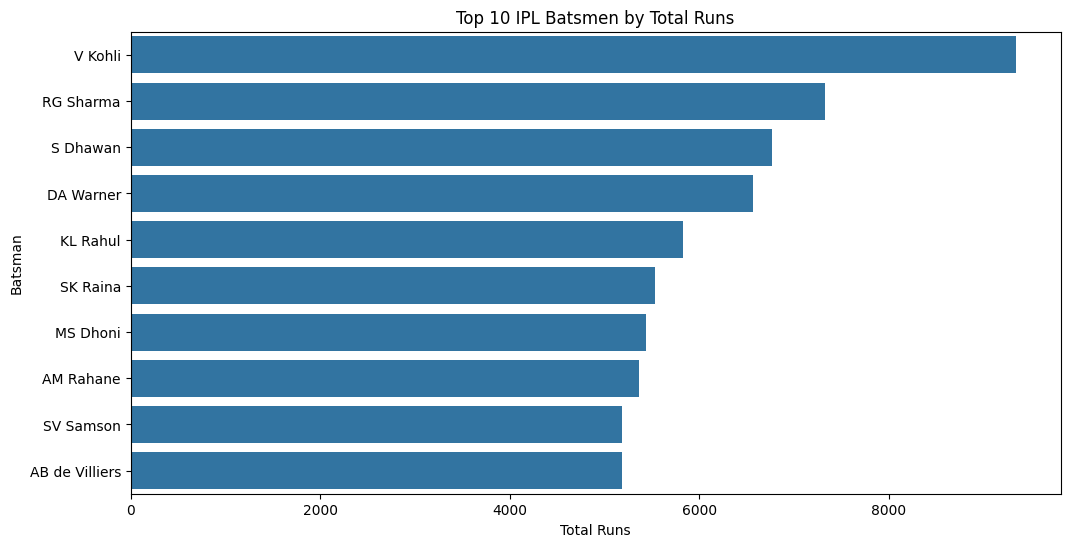

In [20]:
# ==========================================
# Step 19: Top Batsmen Visualization
# ==========================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_batsmen,
    x="total_runs",
    y="striker"
)

plt.title("Top 10 IPL Batsmen by Total Runs")
plt.xlabel("Total Runs")
plt.ylabel("Batsman")
plt.show()

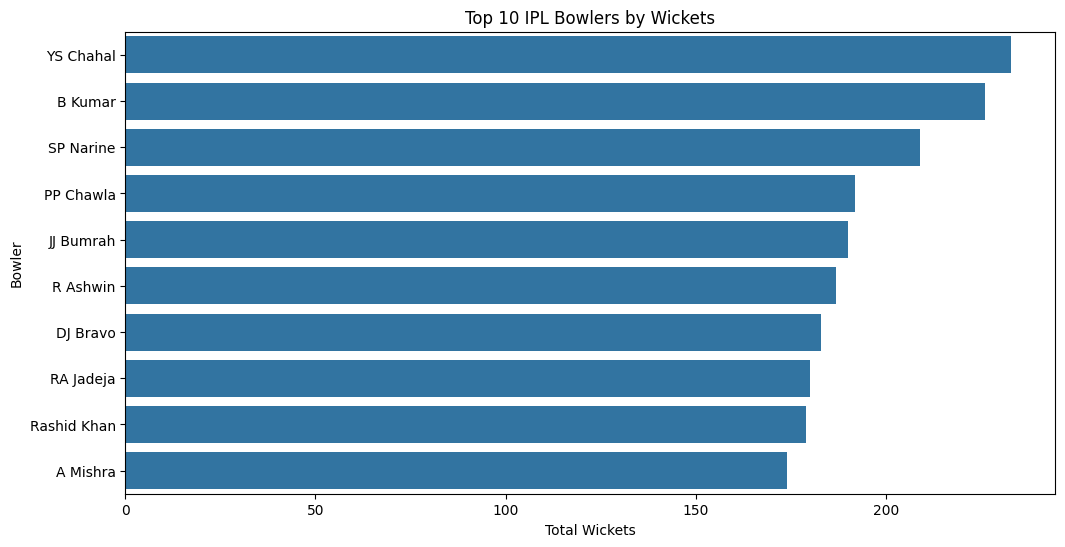

In [21]:
# ==========================================
# Step 20: Top Bowlers Visualization
# ==========================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_bowlers,
    x="wickets",
    y="bowler"
)

plt.title("Top 10 IPL Bowlers by Wickets")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")
plt.show()

In [22]:
# ==========================================
# CricPredict AI
# Step 21: Team Performance Analytics
# ==========================================

# Team runs and wickets
team_performance = ipl_deliveries.groupby(
    "batting_team"
).agg(
    total_runs=("total_runs", "sum"),
    wickets_lost=("is_wicket", "sum"),
    matches_played=("match_id", "nunique")
).reset_index()

# Count wins
team_wins = (
    ipl_matches.groupby("winner")["match_id"]
    .nunique()
    .reset_index()
)

team_wins.columns = ["batting_team", "matches_won"]

# Merge team statistics
team_performance = team_performance.merge(
    team_wins,
    on="batting_team",
    how="left"
)

team_performance["matches_won"] = (
    team_performance["matches_won"].fillna(0)
)

# Win percentage
team_performance["win_percentage"] = (
    team_performance["matches_won"] /
    team_performance["matches_played"]
) * 100

# Average runs per match
team_performance["average_runs"] = (
    team_performance["total_runs"] /
    team_performance["matches_played"]
)

# Sort teams by total runs
team_performance = team_performance.sort_values(
    "total_runs", ascending=False
)

print("========== IPL TEAM PERFORMANCE ==========")

display(team_performance.round(2))

========== IPL TEAM PERFORMANCE ==========


,batting_team,total_runs,wickets_lost,matches_played,matches_won,win_percentage,average_runs
10,Mumbai Indians,47641.0,1749,291,155,53.26,163.71
8,Kolkata Knight Riders,43646.0,1650,278,140,50.36,157.00
0,Chennai Super Kings,43600.0,1424,265,148,55.85,164.53
13,Rajasthan Royals,40437.0,1505,250,123,49.20,161.75
16,Royal Challengers Bangalore,37692.0,1384,240,114,47.50,157.05
18,Sunrisers Hyderabad,34640.0,1242,210,102,48.57,164.95
6,Kings XI Punjab,30064.0,1158,190,85,44.74,158.23
3,Delhi Daredevils,24296.0,952,161,67,41.61,150.91
2,Delhi Capitals,19959.0,745,119,58,48.74,167.72
12,Punjab Kings,15509.0,548,87,41,47.13,178.26


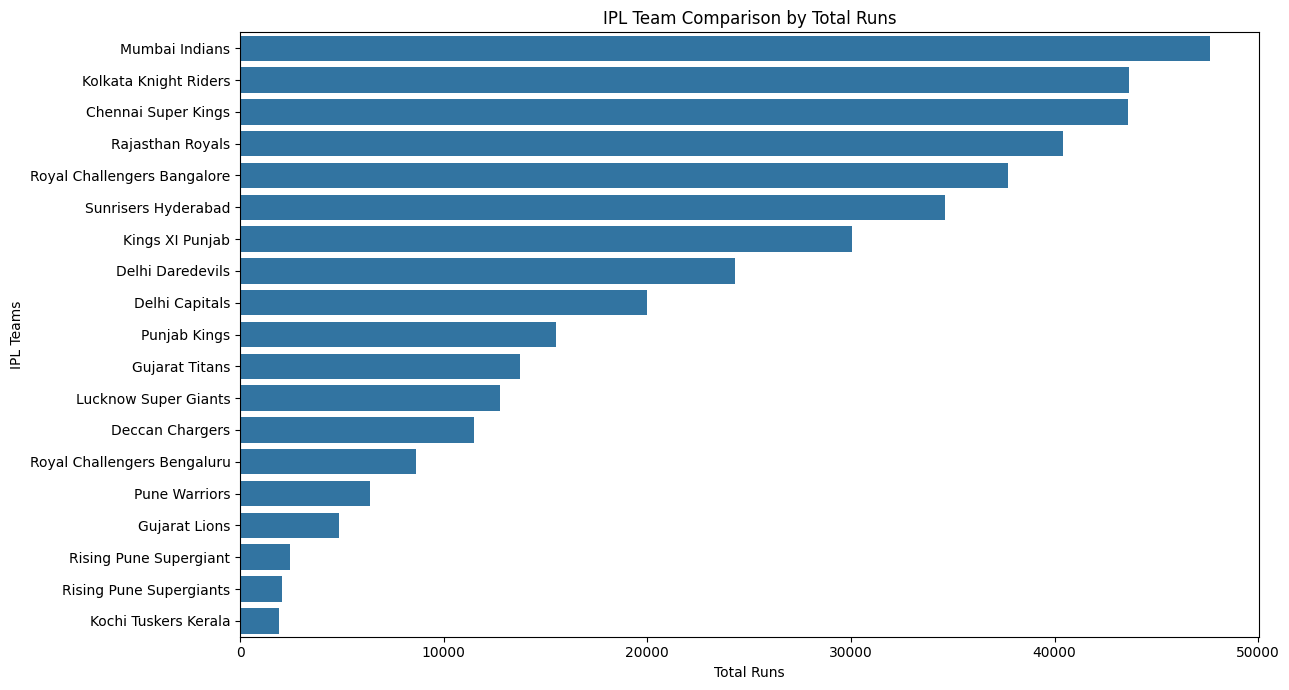

In [23]:
# ==========================================
# Step 22: Team Runs Comparison
# ==========================================

plt.figure(figsize=(13, 7))

sns.barplot(
    data=team_performance,
    x="total_runs",
    y="batting_team"
)

plt.title("IPL Team Comparison by Total Runs")
plt.xlabel("Total Runs")
plt.ylabel("IPL Teams")
plt.tight_layout()
plt.show()

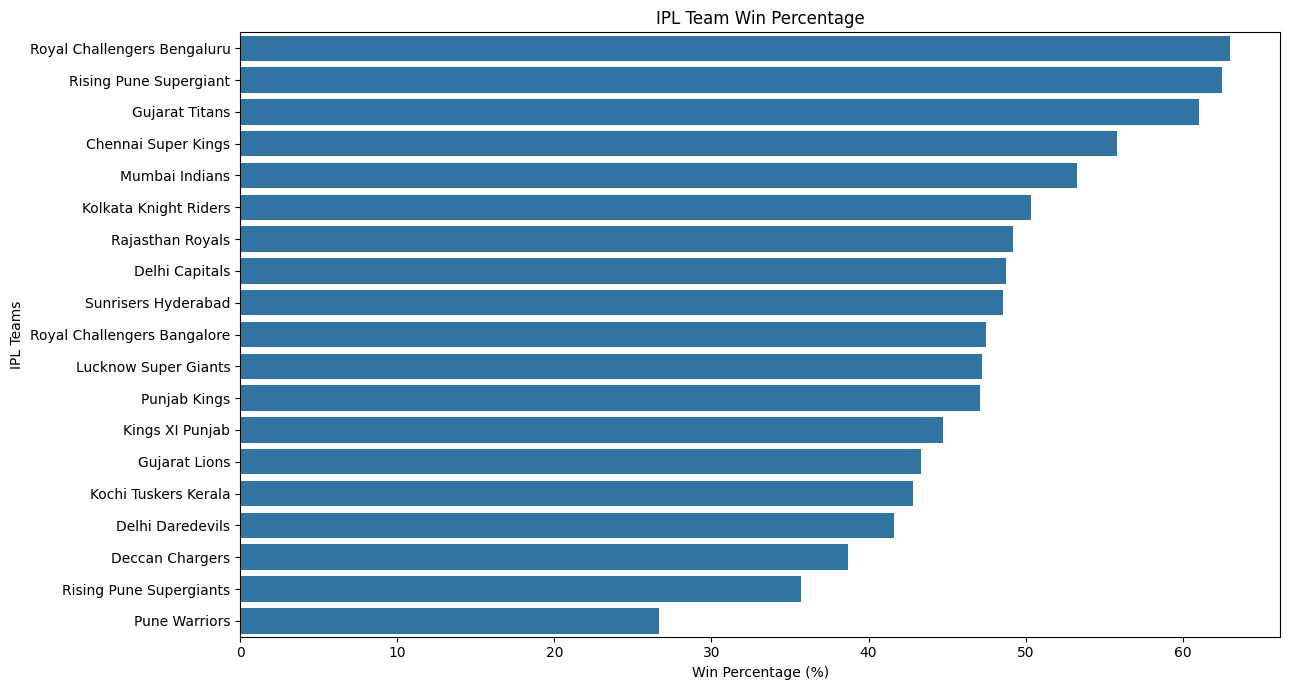

In [24]:
# ==========================================
# Step 23: Team Win Percentage
# ==========================================

plt.figure(figsize=(13, 7))

sns.barplot(
    data=team_performance.sort_values(
        "win_percentage", ascending=False
    ),
    x="win_percentage",
    y="batting_team"
)

plt.title("IPL Team Win Percentage")
plt.xlabel("Win Percentage (%)")
plt.ylabel("IPL Teams")
plt.tight_layout()
plt.show()

In [25]:
# Correct only the RPS spelling variation

ipl_matches["team1"] = ipl_matches["team1"].replace({
    "Rising Pune Supergiants": "Rising Pune Supergiant"
})

ipl_matches["team2"] = ipl_matches["team2"].replace({
    "Rising Pune Supergiants": "Rising Pune Supergiant"
})

ipl_matches["winner"] = ipl_matches["winner"].replace({
    "Rising Pune Supergiants": "Rising Pune Supergiant"
})

ipl_deliveries["batting_team"] = (
    ipl_deliveries["batting_team"].replace({
        "Rising Pune Supergiants": "Rising Pune Supergiant"
    })
)

ipl_deliveries["bowling_team"] = (
    ipl_deliveries["bowling_team"].replace({
        "Rising Pune Supergiants": "Rising Pune Supergiant"
    })
)

print("Historical team names preserved.")
print("Pune Warriors India remains separate.")

Historical team names preserved.
Pune Warriors India remains separate.


In [26]:
# ==========================================
# Step 27: Verify Historical Team Names
# ==========================================

print("TEAMS IN MATCH DATASET:")

teams = sorted(
    set(ipl_matches["team1"].dropna()) |
    set(ipl_matches["team2"].dropna())
)

for team in teams:
    print(team)

print("\nPUNE FRANCHISE CHECK:")

for team in teams:
    if "Pune" in team:
        print(team)

TEAMS IN MATCH DATASET:
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Delhi Daredevils
Gujarat Lions
Gujarat Titans
Kings XI Punjab
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiant
Royal Challengers Bangalore
Royal Challengers Bengaluru
Sunrisers Hyderabad

PUNE FRANCHISE CHECK:
Pune Warriors
Rising Pune Supergiant


In [27]:
# ==========================================
# Step 28: Franchise Mapping
# Preserve Original Historical Team Names
# ==========================================

franchise_mapping = {
    "Royal Challengers Bangalore":
        "Royal Challengers Bengaluru",

    "Kings XI Punjab":
        "Punjab Kings",

    "Delhi Daredevils":
        "Delhi Capitals"
}

# Create separate franchise columns
ipl_matches["team1_franchise"] = (
    ipl_matches["team1"].replace(franchise_mapping)
)

ipl_matches["team2_franchise"] = (
    ipl_matches["team2"].replace(franchise_mapping)
)

ipl_matches["winner_franchise"] = (
    ipl_matches["winner"].replace(franchise_mapping)
)

ipl_deliveries["batting_franchise"] = (
    ipl_deliveries["batting_team"].replace(franchise_mapping)
)

ipl_deliveries["bowling_franchise"] = (
    ipl_deliveries["bowling_team"].replace(franchise_mapping)
)

print("Franchise mapping completed!")

display(
    ipl_matches[
        ["team1", "team1_franchise",
         "team2", "team2_franchise"]
    ].head(10)
)

Franchise mapping completed!


,team1,team1_franchise,team2,team2_franchise
10009,Sunrisers Hyderabad,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bengaluru
10010,Rising Pune Supergiant,Rising Pune Supergiant,Mumbai Indians,Mumbai Indians
10011,Gujarat Lions,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders
10012,Kings XI Punjab,Punjab Kings,Rising Pune Supergiant,Rising Pune Supergiant
10013,Royal Challengers Bangalore,Royal Challengers Bengaluru,Delhi Daredevils,Delhi Capitals
10014,Sunrisers Hyderabad,Sunrisers Hyderabad,Gujarat Lions,Gujarat Lions
10015,Mumbai Indians,Mumbai Indians,Kolkata Knight Riders,Kolkata Knight Riders
10016,Kings XI Punjab,Punjab Kings,Royal Challengers Bangalore,Royal Challengers Bengaluru
10017,Rising Pune Supergiant,Rising Pune Supergiant,Delhi Daredevils,Delhi Capitals
10018,Mumbai Indians,Mumbai Indians,Sunrisers Hyderabad,Sunrisers Hyderabad


In [28]:
# ==========================================
# CricPredict AI
# Step 29.1: Calculate Match Innings Scores
# ==========================================

# Aggregate total runs by match and innings
innings_scores = (
    ipl_deliveries
    .groupby(["match_id", "innings"])["total_runs"]
    .sum()
    .reset_index()
)

# Keep first innings scores
first_innings = innings_scores[
    innings_scores["innings"] == 1
][["match_id", "total_runs"]].copy()

first_innings = first_innings.rename(
    columns={"total_runs": "first_innings_score"}
)

# Keep second innings scores
second_innings = innings_scores[
    innings_scores["innings"] == 2
][["match_id", "total_runs"]].copy()

second_innings = second_innings.rename(
    columns={"total_runs": "second_innings_score"}
)

print("FIRST INNINGS SCORES")
display(first_innings.head())

print("SECOND INNINGS SCORES")
display(second_innings.head())

FIRST INNINGS SCORES


,match_id,first_innings_score
0,335982,222.0
2,335983,240.0
4,335984,129.0
6,335985,165.0
8,335986,110.0


SECOND INNINGS SCORES


,match_id,second_innings_score
1,335982,82.0
3,335983,207.0
5,335984,132.0
7,335985,166.0
9,335986,112.0


In [29]:
# ==========================================
# Step 29.2: Create Match-Level Dataset
# ==========================================

match_ml = ipl_matches.merge(
    first_innings,
    on="match_id",
    how="left"
)

match_ml = match_ml.merge(
    second_innings,
    on="match_id",
    how="left"
)

# Create target score
match_ml["target_score"] = (
    match_ml["first_innings_score"] + 1
)

print("MATCH ML DATASET CREATED")

print("Dataset shape:", match_ml.shape)

display(match_ml.head(10))

MATCH ML DATASET CREATED
Dataset shape: (1243, 51)


,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,tv_umpire2,reserve_umpire2,end_date,match_dates,team1_franchise,team2_franchise,winner_franchise,first_innings_score,second_innings_score,target_score
0,1082591,IPL,Sunrisers Hyderabad,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",...,NaN,NaN,2017-04-05,2017/04/05,Sunrisers Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,207.0,172.0,208.0
1,1082592,IPL,Rising Pune Supergiant,Mumbai Indians,NaN,NaN,male,2017,2017-04-06,"Maharashtra Cricket Association Stadium, Pune",...,NaN,NaN,2017-04-06,2017/04/06,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,184.0,187.0,185.0
2,1082593,IPL,Gujarat Lions,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-07,"Saurashtra Cricket Association Stadium, Rajkot",...,NaN,NaN,2017-04-07,2017/04/07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,183.0,184.0,184.0
3,1082594,IPL,Kings XI Punjab,Rising Pune Supergiant,NaN,NaN,male,2017,2017-04-08,"Holkar Cricket Stadium, Indore",...,NaN,NaN,2017-04-08,2017/04/08,Punjab Kings,Rising Pune Supergiant,Punjab Kings,163.0,164.0,164.0
4,1082595,IPL,Royal Challengers Bangalore,Delhi Daredevils,NaN,NaN,male,2017,2017-04-08,"M Chinnaswamy Stadium, Bengaluru",...,NaN,NaN,2017-04-08,2017/04/08,Royal Challengers Bengaluru,Delhi Capitals,Royal Challengers Bengaluru,157.0,142.0,158.0
5,1082596,IPL,Sunrisers Hyderabad,Gujarat Lions,NaN,NaN,male,2017,2017-04-09,"Rajiv Gandhi International Stadium, Uppal",...,NaN,NaN,2017-04-09,2017/04/09,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,135.0,140.0,136.0
6,1082597,IPL,Mumbai Indians,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-09,"Wankhede Stadium, Mumbai",...,NaN,NaN,2017-04-09,2017/04/09,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,178.0,180.0,179.0
7,1082598,IPL,Kings XI Punjab,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-10,"Holkar Cricket Stadium, Indore",...,NaN,NaN,2017-04-10,2017/04/10,Punjab Kings,Royal Challengers Bengaluru,Punjab Kings,148.0,150.0,149.0
8,1082599,IPL,Rising Pune Supergiant,Delhi Daredevils,NaN,NaN,male,2017,2017-04-11,"Maharashtra Cricket Association Stadium, Pune",...,NaN,NaN,2017-04-11,2017/04/11,Rising Pune Supergiant,Delhi Capitals,Delhi Capitals,205.0,108.0,206.0
9,1082600,IPL,Mumbai Indians,Sunrisers Hyderabad,NaN,NaN,male,2017,2017-04-12,"Wankhede Stadium, Mumbai",...,NaN,NaN,2017-04-12,2017/04/12,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,158.0,159.0,159.0


In [30]:
# ==========================================
# Step 29.3: Check Match-Level Dataset
# ==========================================

print("MISSING VALUES:")

print(
    match_ml[
        ["first_innings_score",
         "second_innings_score",
         "winner"]
    ].isnull().sum()
)

print("\nMATCH DATASET INFORMATION:")

match_ml.info()

MISSING VALUES:
first_innings_score      0
second_innings_score     6
winner                  25
dtype: int64

MATCH DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 51 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   match_id              1243 non-null   int64  
 1   match_type            1243 non-null   object 
 2   team1                 1243 non-null   object 
 3   team2                 1243 non-null   object 
 4   team1_icc_type        0 non-null      object 
 5   team2_icc_type        0 non-null      object 
 6   gender                1243 non-null   object 
 7   season                1243 non-null   object 
 8   start_date            1243 non-null   object 
 9   venue                 1243 non-null   object 
 10  city                  1192 non-null   object 
 11  event                 1243 non-null   object 
 12  match_number          1169 non-null 

In [31]:
# ==========================================
# CricPredict AI
# Step 29.4: Verify ML Dataset
# ==========================================

important_columns = [
    "match_id",
    "team1",
    "team2",
    "season",
    "venue",
    "toss_winner",
    "winner",
    "first_innings_score",
    "second_innings_score",
    "target_score"
]

# Display only available columns
available_columns = [
    col for col in important_columns
    if col in match_ml.columns
]

display(match_ml[available_columns].head(10))

print("\nDATASET SHAPE:", match_ml.shape)

print("\nMISSING VALUES:")
print(match_ml[available_columns].isnull().sum())

print("\nMATCH WINNER COUNTS:")
print(match_ml["winner"].value_counts().head(10))

,match_id,team1,team2,season,venue,toss_winner,winner,first_innings_score,second_innings_score,target_score
0,1082591,Sunrisers Hyderabad,Royal Challengers Bangalore,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Sunrisers Hyderabad,207.0,172.0,208.0
1,1082592,Rising Pune Supergiant,Mumbai Indians,2017,"Maharashtra Cricket Association Stadium, Pune",Rising Pune Supergiant,Rising Pune Supergiant,184.0,187.0,185.0
2,1082593,Gujarat Lions,Kolkata Knight Riders,2017,"Saurashtra Cricket Association Stadium, Rajkot",Kolkata Knight Riders,Kolkata Knight Riders,183.0,184.0,184.0
3,1082594,Kings XI Punjab,Rising Pune Supergiant,2017,"Holkar Cricket Stadium, Indore",Kings XI Punjab,Kings XI Punjab,163.0,164.0,164.0
4,1082595,Royal Challengers Bangalore,Delhi Daredevils,2017,"M Chinnaswamy Stadium, Bengaluru",Royal Challengers Bangalore,Royal Challengers Bangalore,157.0,142.0,158.0
5,1082596,Sunrisers Hyderabad,Gujarat Lions,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Sunrisers Hyderabad,135.0,140.0,136.0
6,1082597,Mumbai Indians,Kolkata Knight Riders,2017,"Wankhede Stadium, Mumbai",Mumbai Indians,Mumbai Indians,178.0,180.0,179.0
7,1082598,Kings XI Punjab,Royal Challengers Bangalore,2017,"Holkar Cricket Stadium, Indore",Royal Challengers Bangalore,Kings XI Punjab,148.0,150.0,149.0
8,1082599,Rising Pune Supergiant,Delhi Daredevils,2017,"Maharashtra Cricket Association Stadium, Pune",Rising Pune Supergiant,Delhi Daredevils,205.0,108.0,206.0
9,1082600,Mumbai Indians,Sunrisers Hyderabad,2017,"Wankhede Stadium, Mumbai",Mumbai Indians,Mumbai Indians,158.0,159.0,159.0



DATASET SHAPE: (1243, 51)

MISSING VALUES:
match_id                 0
team1                    0
team2                    0
season                   0
venue                    0
toss_winner              0
winner                  25
first_innings_score      0
second_innings_score     6
target_score             0
dtype: int64

MATCH WINNER COUNTS:
winner
Mumbai Indians                 155
Chennai Super Kings            148
Kolkata Knight Riders          140
Rajasthan Royals               123
Royal Challengers Bangalore    114
Sunrisers Hyderabad            102
Kings XI Punjab                 85
Delhi Daredevils                67
Delhi Capitals                  58
Gujarat Titans                  47
Name: count, dtype: int64


In [32]:
# ==========================================
# CricPredict AI
# STEP 30: FEATURE ENGINEERING
# ==========================================

import pandas as pd
import numpy as np

# Create a copy
model_data = match_ml.copy()

# Remove incomplete records
model_data = model_data.dropna(
    subset=[
        "team1",
        "team2",
        "winner",
        "first_innings_score",
        "second_innings_score"
    ]
)

# Create match outcome
model_data["team1_win"] = (
    model_data["winner"] == model_data["team1"]
).astype(int)

# Create score difference
model_data["score_difference"] = (
    model_data["first_innings_score"] -
    model_data["second_innings_score"]
)

# Create target
model_data["target_score"] = (
    model_data["first_innings_score"] + 1
)

print("FEATURE ENGINEERING COMPLETED")
print("Dataset shape:", model_data.shape)

display(model_data.head(10))

FEATURE ENGINEERING COMPLETED
Dataset shape: (1218, 53)


,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,end_date,match_dates,team1_franchise,team2_franchise,winner_franchise,first_innings_score,second_innings_score,target_score,team1_win,score_difference
0,1082591,IPL,Sunrisers Hyderabad,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",...,2017-04-05,2017/04/05,Sunrisers Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,207.0,172.0,208.0,1,35.0
1,1082592,IPL,Rising Pune Supergiant,Mumbai Indians,NaN,NaN,male,2017,2017-04-06,"Maharashtra Cricket Association Stadium, Pune",...,2017-04-06,2017/04/06,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,184.0,187.0,185.0,1,-3.0
2,1082593,IPL,Gujarat Lions,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-07,"Saurashtra Cricket Association Stadium, Rajkot",...,2017-04-07,2017/04/07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,183.0,184.0,184.0,0,-1.0
3,1082594,IPL,Kings XI Punjab,Rising Pune Supergiant,NaN,NaN,male,2017,2017-04-08,"Holkar Cricket Stadium, Indore",...,2017-04-08,2017/04/08,Punjab Kings,Rising Pune Supergiant,Punjab Kings,163.0,164.0,164.0,1,-1.0
4,1082595,IPL,Royal Challengers Bangalore,Delhi Daredevils,NaN,NaN,male,2017,2017-04-08,"M Chinnaswamy Stadium, Bengaluru",...,2017-04-08,2017/04/08,Royal Challengers Bengaluru,Delhi Capitals,Royal Challengers Bengaluru,157.0,142.0,158.0,1,15.0
5,1082596,IPL,Sunrisers Hyderabad,Gujarat Lions,NaN,NaN,male,2017,2017-04-09,"Rajiv Gandhi International Stadium, Uppal",...,2017-04-09,2017/04/09,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,135.0,140.0,136.0,1,-5.0
6,1082597,IPL,Mumbai Indians,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-09,"Wankhede Stadium, Mumbai",...,2017-04-09,2017/04/09,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,178.0,180.0,179.0,1,-2.0
7,1082598,IPL,Kings XI Punjab,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-10,"Holkar Cricket Stadium, Indore",...,2017-04-10,2017/04/10,Punjab Kings,Royal Challengers Bengaluru,Punjab Kings,148.0,150.0,149.0,1,-2.0
8,1082599,IPL,Rising Pune Supergiant,Delhi Daredevils,NaN,NaN,male,2017,2017-04-11,"Maharashtra Cricket Association Stadium, Pune",...,2017-04-11,2017/04/11,Rising Pune Supergiant,Delhi Capitals,Delhi Capitals,205.0,108.0,206.0,0,97.0
9,1082600,IPL,Mumbai Indians,Sunrisers Hyderabad,NaN,NaN,male,2017,2017-04-12,"Wankhede Stadium, Mumbai",...,2017-04-12,2017/04/12,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,158.0,159.0,159.0,1,-1.0


In [33]:
# ==========================================
# CricPredict AI
# STEP 31: DATA QUALITY CHECK
# ==========================================

print("DATASET INFORMATION")
print("===================")

print("Shape:", model_data.shape)

print("\nTARGET DISTRIBUTION:")
print(model_data["team1_win"].value_counts())

print("\nTARGET PERCENTAGE:")
print(
    model_data["team1_win"]
    .value_counts(normalize=True) * 100
)

print("\nMISSING VALUES:")
print(
    model_data.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nDUPLICATE MATCH IDs:")
print(model_data["match_id"].duplicated().sum())

print("\nDATA QUALITY CHECK COMPLETED")

DATASET INFORMATION
Shape: (1218, 53)

TARGET DISTRIBUTION:
team1_win
0    610
1    608
Name: count, dtype: int64

TARGET PERCENTAGE:
team1_win
0    50.082102
1    49.917898
Name: proportion, dtype: float64

MISSING VALUES:
team1_icc_type       1218
team2_icc_type       1218
bowl_out             1218
winner_innings       1218
outcome              1218
toss_uncontested     1218
super_over           1218
match_type_number    1218
player_of_match2     1218
tv_umpire2           1218
reserve_umpire2      1218
umpire3              1218
umpire4              1218
eliminator           1218
declared             1218
method               1195
winner_runs           660
winner_wickets        558
match_number           74
city                   48
dtype: int64

DUPLICATE MATCH IDs:
0

DATA QUALITY CHECK COMPLETED


In [34]:
# ==========================================
# CricPredict AI
# STEP 32: SELECT ML FEATURES
# ==========================================

# Select only pre-match information
features = [
    "team1",
    "team2",
    "toss_winner",
    "toss_decision",
    "venue",
    "season"
]

target = "team1_win"

# Create ML dataset
ml_data = model_data[features + [target]].copy()

# Remove incomplete records
ml_data = ml_data.dropna()

# Remove matches where team names are identical
ml_data = ml_data[
    ml_data["team1"] != ml_data["team2"]
]

print("ML DATASET READY")
print("================")

print("Features:", features)
print("Target:", target)
print("Dataset shape:", ml_data.shape)

print("\nMissing values:")
print(ml_data.isnull().sum())

display(ml_data.head(10))

ML DATASET READY
Features: ['team1', 'team2', 'toss_winner', 'toss_decision', 'venue', 'season']
Target: team1_win
Dataset shape: (1218, 7)

Missing values:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
team1_win        0
dtype: int64


,team1,team2,toss_winner,toss_decision,venue,season,team1_win
0,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,"Rajiv Gandhi International Stadium, Uppal",2017,1
1,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,"Maharashtra Cricket Association Stadium, Pune",2017,1
2,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,"Saurashtra Cricket Association Stadium, Rajkot",2017,0
3,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,"Holkar Cricket Stadium, Indore",2017,1
4,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,"M Chinnaswamy Stadium, Bengaluru",2017,1
5,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,field,"Rajiv Gandhi International Stadium, Uppal",2017,1
6,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,field,"Wankhede Stadium, Mumbai",2017,1
7,Kings XI Punjab,Royal Challengers Bangalore,Royal Challengers Bangalore,bat,"Holkar Cricket Stadium, Indore",2017,1
8,Rising Pune Supergiant,Delhi Daredevils,Rising Pune Supergiant,field,"Maharashtra Cricket Association Stadium, Pune",2017,0
9,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,field,"Wankhede Stadium, Mumbai",2017,1


In [35]:
# ==========================================
# CricPredict AI
# STEP 32B: CLEAN SELECTED FEATURES
# ==========================================

features = [
    "team1",
    "team2",
    "toss_winner",
    "toss_decision",
    "venue",
    "season"
]

target = "team1_win"

# Create clean working dataset
ml_data = model_data[features + [target]].copy()

print("BEFORE CLEANING:", ml_data.shape)

# Check missing values
print("\nMISSING VALUES:")
print(ml_data.isnull().sum())

# Remove rows missing essential information
ml_data = ml_data.dropna(
    subset=features + [target]
)

# Remove invalid matches
ml_data = ml_data[
    ml_data["team1"] != ml_data["team2"]
]

print("\nAFTER CLEANING:", ml_data.shape)

print("\nFINAL MISSING VALUES:")
print(ml_data.isnull().sum())

print("\nCLEAN DATASET READY")
display(ml_data.head(10))

BEFORE CLEANING: (1218, 7)

MISSING VALUES:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
team1_win        0
dtype: int64

AFTER CLEANING: (1218, 7)

FINAL MISSING VALUES:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
team1_win        0
dtype: int64

CLEAN DATASET READY


,team1,team2,toss_winner,toss_decision,venue,season,team1_win
0,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,"Rajiv Gandhi International Stadium, Uppal",2017,1
1,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,"Maharashtra Cricket Association Stadium, Pune",2017,1
2,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,"Saurashtra Cricket Association Stadium, Rajkot",2017,0
3,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,"Holkar Cricket Stadium, Indore",2017,1
4,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,"M Chinnaswamy Stadium, Bengaluru",2017,1
5,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,field,"Rajiv Gandhi International Stadium, Uppal",2017,1
6,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,field,"Wankhede Stadium, Mumbai",2017,1
7,Kings XI Punjab,Royal Challengers Bangalore,Royal Challengers Bangalore,bat,"Holkar Cricket Stadium, Indore",2017,1
8,Rising Pune Supergiant,Delhi Daredevils,Rising Pune Supergiant,field,"Maharashtra Cricket Association Stadium, Pune",2017,0
9,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,field,"Wankhede Stadium, Mumbai",2017,1


In [36]:
# ==========================================
# CricPredict AI
# STEP 33: CATEGORICAL ENCODING
# ==========================================

from sklearn.preprocessing import OrdinalEncoder

# Copy clean dataset
encoded_data = ml_data.copy()

# Categorical columns
categorical_features = [
    "team1",
    "team2",
    "toss_winner",
    "toss_decision",
    "venue"
]

# Encode categorical values
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

encoded_data[categorical_features] = encoder.fit_transform(
    encoded_data[categorical_features].astype(str)
)

print("ENCODING COMPLETED")

print("\nENCODED DATASET:")
display(encoded_data.head(10))

print("\nFINAL SHAPE:", encoded_data.shape)

ENCODING COMPLETED

ENCODED DATASET:


,team1,team2,toss_winner,toss_decision,venue,season,team1_win
0,17.0,15.0,16.0,1.0,28.0,2017,1
1,14.0,10.0,14.0,1.0,21.0,2017,1
2,4.0,8.0,8.0,1.0,30.0,2017,0
3,6.0,14.0,6.0,1.0,14.0,2017,1
4,15.0,3.0,16.0,0.0,18.0,2017,1
5,17.0,4.0,18.0,1.0,28.0,2017,1
6,10.0,8.0,10.0,1.0,40.0,2017,1
7,6.0,15.0,16.0,0.0,14.0,2017,1
8,14.0,3.0,14.0,1.0,21.0,2017,0
9,10.0,17.0,10.0,1.0,40.0,2017,1



FINAL SHAPE: (1218, 7)


In [37]:
# ==========================================
# STEP 34: TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Separate features and target
X = encoded_data.drop(columns=["team1_win"])
y = encoded_data["team1_win"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN TEST SPLIT COMPLETED")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

TRAIN TEST SPLIT COMPLETED
Training features: (974, 6)
Testing features: (244, 6)
Training target: (974,)
Testing target: (244,)


In [40]:
# ==========================================
# FIX: CONVERT SEASON INTO NUMERIC FORMAT
# ==========================================

# Convert season values such as 2020/21 to 2020
X_train["season"] = (
    X_train["season"].astype(str).str[:4].astype(int)
)

X_test["season"] = (
    X_test["season"].astype(str).str[:4].astype(int)
)

print("SEASON CONVERSION COMPLETED")

print("Training season values:")
print(X_train["season"].head())

print("\nTesting season values:")
print(X_test["season"].head())

print("\nData types:")
print(X_train.dtypes)

SEASON CONVERSION COMPLETED
Training season values:
757    2009
334    2022
136    2019
998    2013
210    2020
Name: season, dtype: int64

Testing season values:
106     2018
365     2022
843     2011
1211    2016
745     2009
Name: season, dtype: int64

Data types:
team1            float64
team2            float64
toss_winner      float64
toss_decision    float64
venue            float64
season             int64
dtype: object


In [41]:
# STEP 35A: CHECK MISSING VALUES

print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X_train.select_dtypes(include="number")).sum())

Missing values in training data:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
dtype: int64

Missing values in testing data:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
dtype: int64

Infinite values:
team1            0
team2            0
toss_winner      0
toss_decision    0
venue            0
season           0
dtype: int64


In [42]:
# ==========================================
# STEP 36: RANDOM FOREST MODEL TRAINING
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate model
print("RANDOM FOREST MODEL RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST MODEL RESULTS
Accuracy: 0.4426229508196721

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.46      0.45       122
           1       0.44      0.43      0.43       122

    accuracy                           0.44       244
   macro avg       0.44      0.44      0.44       244
weighted avg       0.44      0.44      0.44       244



In [43]:
# STEP 37: MODEL DATA INSPECTION

print("FEATURES:")
print(X_train.head(10))

print("\nTARGET:")
print(y_train.head(10))

print("\nTARGET DISTRIBUTION:")
print(y_train.value_counts())

print("\nFEATURE CORRELATION:")
print(X_train.corr())

FEATURES:
     team1  team2  toss_winner  toss_decision  venue  season
757    1.0    6.0          6.0            1.0    7.0    2009
334   15.0   17.0         18.0            1.0    5.0    2022
136    0.0    6.0          0.0            0.0   19.0    2019
998   15.0    8.0         16.0            1.0   17.0    2013
210    8.0    6.0          8.0            0.0   34.0    2020
405    0.0    8.0          8.0            1.0   10.0    2023
856   11.0    3.0          3.0            1.0    8.0    2011
705   10.0    8.0         10.0            1.0   40.0    2007
218   15.0    6.0         16.0            0.0   33.0    2020
665    5.0   16.0         17.0            1.0   23.0    2026

TARGET:
757    0
334    0
136    1
998    1
210    1
405    1
856    0
705    1
218    0
665    0
Name: team1_win, dtype: int64

TARGET DISTRIBUTION:
team1_win
0    488
1    486
Name: count, dtype: int64

FEATURE CORRELATION:
                  team1     team2  toss_winner  toss_decision     venue  \
team1          1.

In [47]:
# Categorical columns
categorical_cols = [
    'team1',
    'team2',
    'toss_winner',
    'toss_decision',
    'venue'
]

# Apply One-Hot Encoding
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    dtype=int
)

print("ENCODING COMPLETED")
print("Original shape:", X.shape)
print("Encoded shape:", X_encoded.shape)

display(X_encoded.head())

ENCODING COMPLETED
Original shape: (1218, 6)
Encoded shape: (1218, 99)


,season,team1_0.0,team1_1.0,team1_2.0,team1_3.0,team1_4.0,team1_5.0,team1_6.0,team1_7.0,team1_8.0,...,venue_31.0,venue_32.0,venue_33.0,venue_34.0,venue_35.0,venue_36.0,venue_37.0,venue_38.0,venue_39.0,venue_40.0
0,2017,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2017,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2017,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2017,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2017,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [48]:
from sklearn.model_selection import train_test_split

# Split encoded features and target
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN-TEST SPLIT COMPLETED")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

TRAIN-TEST SPLIT COMPLETED
Training features: (974, 99)
Testing features: (244, 99)
Training target: (974,)
Testing target: (244,)


In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate model
print("RANDOM FOREST MODEL RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

ValueError: could not convert string to float: '2020/21'

In [50]:
# Fix season values such as 2020/21
X = X.copy()

X['season'] = (
    X['season']
    .astype(str)
    .str.extract(r'(\d{4})')[0]
)

X['season'] = pd.to_numeric(
    X['season'], errors='coerce'
)

print("SEASON CONVERSION COMPLETED")
print(X['season'].unique())
print("Missing seasons:", X['season'].isna().sum())

SEASON CONVERSION COMPLETED
[2017 2018 2019 2020 2021 2022 2023 2024 2025 2026 2007 2009 2011 2012
 2013 2014 2015 2016]
Missing seasons: 0


In [51]:
categorical_cols = [
    'team1',
    'team2',
    'toss_winner',
    'toss_decision',
    'venue'
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    dtype=int
)

print("ENCODING COMPLETED")
print("Encoded shape:", X_encoded.shape)
print("Missing values:", X_encoded.isnull().sum().sum())

ENCODING COMPLETED
Encoded shape: (1218, 99)
Missing values: 0


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN TEST SPLIT COMPLETED")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

TRAIN TEST SPLIT COMPLETED
Training: (974, 99)
Testing: (244, 99)


In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

# Train model
rf_model.fit(X_train, y_train)

# Predict test results
y_pred_rf = rf_model.predict(X_test)

# Evaluate performance
print("RANDOM FOREST MODEL RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST MODEL RESULTS
Accuracy: 0.5245901639344263

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.56      0.54       122
           1       0.53      0.49      0.51       122

    accuracy                           0.52       244
   macro avg       0.52      0.52      0.52       244
weighted avg       0.52      0.52      0.52       244



In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train model
lr_model.fit(X_train, y_train)

# Prediction
y_pred_lr = lr_model.predict(X_test)

# Evaluation
print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.5163934426229508

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.52      0.52       122
           1       0.52      0.52      0.52       122

    accuracy                           0.52       244
   macro avg       0.52      0.52      0.52       244
weighted avg       0.52      0.52      0.52       244



In [55]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=10,
    random_state=42
)

# Train
dt_model.fit(X_train, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test)

# Evaluate
print("DECISION TREE RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

DECISION TREE RESULTS
Accuracy: 0.5286885245901639

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.64      0.58       122
           1       0.54      0.42      0.47       122

    accuracy                           0.53       244
   macro avg       0.53      0.53      0.52       244
weighted avg       0.53      0.53      0.52       244



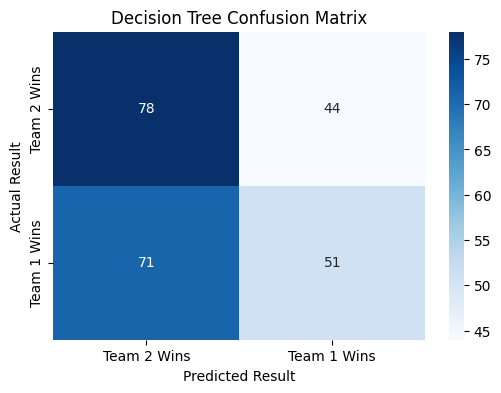

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Decision Tree confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Team 2 Wins', 'Team 1 Wins'],
    yticklabels=['Team 2 Wins', 'Team 1 Wins']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()

TOP 10 IMPORTANT FEATURES:
season              0.166235
team2_3.0           0.065004
venue_11.0          0.060231
venue_12.0          0.051721
toss_winner_1.0     0.050803
team2_6.0           0.046600
venue_25.0          0.041216
team2_12.0          0.036690
team1_0.0           0.033710
toss_winner_14.0    0.031025
dtype: float64


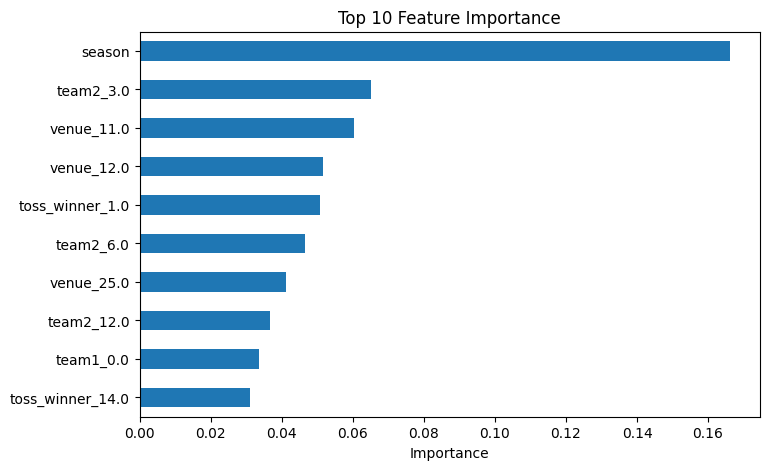

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("TOP 10 IMPORTANT FEATURES:")
print(importance.head(10))

importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(8, 5),
    title="Top 10 Feature Importance"
)

plt.xlabel("Importance")
plt.show()

TOP 10 IMPORTANT FEATURES:
season              0.166235
team2_3.0           0.065004
venue_11.0          0.060231
venue_12.0          0.051721
toss_winner_1.0     0.050803
team2_6.0           0.046600
venue_25.0          0.041216
team2_12.0          0.036690
team1_0.0           0.033710
toss_winner_14.0    0.031025
dtype: float64


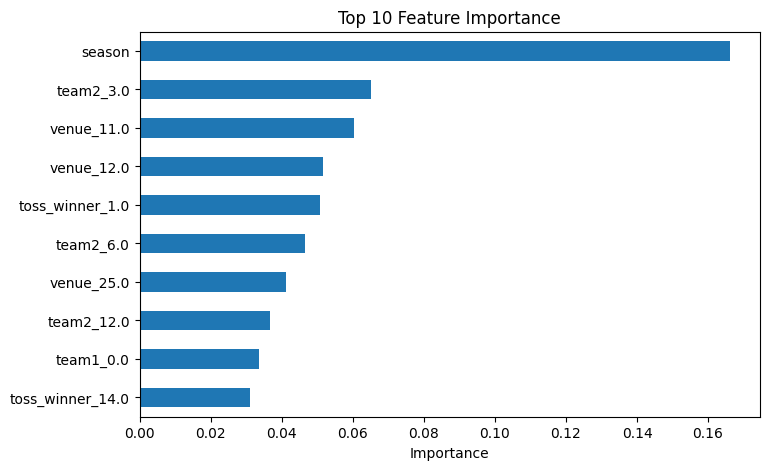

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("TOP 10 IMPORTANT FEATURES:")
print(importance.head(10))

importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(8, 5),
    title="Top 10 Feature Importance"
)

plt.xlabel("Importance")
plt.show()

In [59]:
print("MODEL:", type(dt_model).__name__)

print("\nFEATURE COLUMNS:")
print(list(X_train.columns))

print("\nAVAILABLE DATA:")
print("X shape:", X.shape)
print("X_train shape:", X_train.shape)

print("\nAVAILABLE ENCODERS:")
for name, obj in globals().copy().items():
    if "encoder" in name.lower():
        print(name, type(obj).__name__)

print("\nTEAM VALUES:")
for col in ['team1', 'team2', 'toss_winner']:
    if col in X.columns:
        print(col, sorted(X[col].dropna().unique()))

print("\nTOSS DECISION VALUES:")
if 'toss_decision' in X.columns:
    print(X['toss_decision'].unique())

print("\nVENUE VALUES:")
if 'venue' in X.columns:
    print(sorted(X['venue'].dropna().unique()))

MODEL: DecisionTreeClassifier

FEATURE COLUMNS:
['season', 'team1_0.0', 'team1_1.0', 'team1_2.0', 'team1_3.0', 'team1_4.0', 'team1_5.0', 'team1_6.0', 'team1_7.0', 'team1_8.0', 'team1_9.0', 'team1_10.0', 'team1_11.0', 'team1_12.0', 'team1_13.0', 'team1_14.0', 'team1_15.0', 'team1_16.0', 'team1_17.0', 'team2_0.0', 'team2_1.0', 'team2_2.0', 'team2_3.0', 'team2_4.0', 'team2_5.0', 'team2_6.0', 'team2_7.0', 'team2_8.0', 'team2_9.0', 'team2_10.0', 'team2_11.0', 'team2_12.0', 'team2_13.0', 'team2_14.0', 'team2_15.0', 'team2_16.0', 'team2_17.0', 'toss_winner_0.0', 'toss_winner_1.0', 'toss_winner_2.0', 'toss_winner_3.0', 'toss_winner_4.0', 'toss_winner_5.0', 'toss_winner_6.0', 'toss_winner_7.0', 'toss_winner_8.0', 'toss_winner_9.0', 'toss_winner_10.0', 'toss_winner_11.0', 'toss_winner_12.0', 'toss_winner_13.0', 'toss_winner_14.0', 'toss_winner_15.0', 'toss_winner_16.0', 'toss_winner_17.0', 'toss_winner_18.0', 'toss_decision_0.0', 'toss_decision_1.0', 'venue_0.0', 'venue_1.0', 'venue_2.0', 'venue

In [60]:
print("ENCODER COLUMN MAPPING")

for col, categories in zip(
    encoder.feature_names_in_,
    encoder.categories_
):
    print(f"\n{col}:")
    for index, value in enumerate(categories):
        print(f"{index} = {value}")

print("\nTARGET MAPPING:")
print("0 = Team 2 wins")
print("1 = Team 1 wins")

ENCODER COLUMN MAPPING

team1:
0 = Chennai Super Kings
1 = Deccan Chargers
2 = Delhi Capitals
3 = Delhi Daredevils
4 = Gujarat Lions
5 = Gujarat Titans
6 = Kings XI Punjab
7 = Kochi Tuskers Kerala
8 = Kolkata Knight Riders
9 = Lucknow Super Giants
10 = Mumbai Indians
11 = Pune Warriors
12 = Punjab Kings
13 = Rajasthan Royals
14 = Rising Pune Supergiant
15 = Royal Challengers Bangalore
16 = Royal Challengers Bengaluru
17 = Sunrisers Hyderabad

team2:
0 = Chennai Super Kings
1 = Deccan Chargers
2 = Delhi Capitals
3 = Delhi Daredevils
4 = Gujarat Lions
5 = Gujarat Titans
6 = Kings XI Punjab
7 = Kochi Tuskers Kerala
8 = Kolkata Knight Riders
9 = Lucknow Super Giants
10 = Mumbai Indians
11 = Pune Warriors
12 = Punjab Kings
13 = Rajasthan Royals
14 = Rising Pune Supergiant
15 = Royal Challengers Bangalore
16 = Royal Challengers Bengaluru
17 = Sunrisers Hyderabad

toss_winner:
0 = Chennai Super Kings
1 = Deccan Chargers
2 = Delhi Capitals
3 = Delhi Daredevils
4 = Gujarat Lions
5 = Gujarat Tit

In [61]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# =====================================
# 1. GET ORIGINAL CATEGORY MAPPINGS
# =====================================

categories = {
    col: list(values)
    for col, values in zip(
        encoder.feature_names_in_,
        encoder.categories_
    )
}

teams = [str(x) for x in categories['team1']]
venues = [str(x) for x in categories['venue']]

team1_map = {
    str(value): float(i)
    for i, value in enumerate(categories['team1'])
}

team2_map = {
    str(value): float(i)
    for i, value in enumerate(categories['team2'])
}

toss_map = {
    str(value): float(i)
    for i, value in enumerate(categories['toss_winner'])
}

venue_map = {
    str(value): float(i)
    for i, value in enumerate(categories['venue'])
}

decision_map = {
    str(value): float(i)
    for i, value in enumerate(categories['toss_decision'])
}

# =====================================
# 2. CREATE INPUT WIDGETS
# =====================================

team1_dropdown = widgets.Dropdown(
    options=teams,
    description='Team 1:',
    layout=widgets.Layout(width='450px')
)

team2_dropdown = widgets.Dropdown(
    options=teams,
    value=teams[1],
    description='Team 2:',
    layout=widgets.Layout(width='450px')
)

toss_dropdown = widgets.Dropdown(
    options=teams,
    description='Toss Winner:',
    layout=widgets.Layout(width='450px')
)

venue_dropdown = widgets.Dropdown(
    options=venues,
    description='Venue:',
    layout=widgets.Layout(width='650px')
)

decision_dropdown = widgets.Dropdown(
    options=['bat', 'field'],
    description='Decision:',
    layout=widgets.Layout(width='450px')
)

season_values = sorted(
    pd.to_numeric(X['season']).dropna().unique()
)

season_dropdown = widgets.Dropdown(
    options=season_values,
    value=int(max(season_values)),
    description='Season:',
    layout=widgets.Layout(width='450px')
)

predict_button = widgets.Button(
    description='PREDICT MATCH WINNER',
    button_style='success',
    icon='check'
)

output = widgets.Output()

# =====================================
# 3. PREDICTION FUNCTION
# =====================================

def predict_match(b):

    with output:
        clear_output()

        team1 = team1_dropdown.value
        team2 = team2_dropdown.value
        toss_winner = toss_dropdown.value
        venue = venue_dropdown.value
        decision = decision_dropdown.value
        season = season_dropdown.value

        if team1 == team2:
            print("Error: Select two different teams.")
            return

        if toss_winner not in [team1, team2]:
            print("Error: Toss winner must be Team 1 or Team 2.")
            return

        # Create zero-filled input
        input_data = pd.DataFrame(
            0.0,
            index=[0],
            columns=X_train.columns
        )

        # Set season
        input_data.loc[0, 'season'] = season

        # Set one-hot encoded values
        features = {
            'team1': team1_map[team1],
            'team2': team2_map[team2],
            'toss_winner': toss_map[toss_winner],
            'toss_decision': decision_map[decision],
            'venue': venue_map[venue]
        }

        for column, value in features.items():
            dummy_column = f"{column}_{value}"

            if dummy_column not in input_data.columns:
                print("Missing model feature:", dummy_column)
                return

            input_data.loc[0, dummy_column] = 1.0

        # Predict
        prediction = dt_model.predict(input_data)[0]

        probabilities = dt_model.predict_proba(input_data)[0]

        class_index = list(dt_model.classes_).index(prediction)

        confidence = probabilities[class_index] * 100

        if prediction == 1:
            winner = team1
        else:
            winner = team2

        # Display result
        print("=" * 45)
        print("       CRICPREDICT AI")
        print("       MATCH PREDICTION")
        print("=" * 45)

        print("\nTeam 1:", team1)
        print("Team 2:", team2)
        print("Toss Winner:", toss_winner)
        print("Toss Decision:", decision)
        print("Venue:", venue)
        print("Season:", season)

        print("\n" + "=" * 45)
        print("PREDICTED WINNER:", winner)
        print("MODEL CLASS PROBABILITY:",
              round(confidence, 2), "%")
        print("=" * 45)

        print(
            "\nNote: This is a Decision Tree model estimate, "
            "not a guaranteed match outcome."
        )

predict_button.on_click(predict_match)

# =====================================
# 4. DISPLAY INTERFACE
# =====================================

display(HTML("""
<h2 style="color:#1976D2;">CRICPREDICT AI</h2>
<h3>IPL Match Winner Prediction System</h3>
<p>Select match details and click the prediction button.</p>
"""))

display(team1_dropdown)
display(team2_dropdown)
display(toss_dropdown)
display(venue_dropdown)
display(decision_dropdown)
display(season_dropdown)
display(predict_button)
display(output)

Dropdown(description='Team 1:', layout=Layout(width='450px'), options=('Chennai Super Kings', 'Deccan Chargers…

Dropdown(description='Team 2:', index=1, layout=Layout(width='450px'), options=('Chennai Super Kings', 'Deccan…

Dropdown(description='Toss Winner:', layout=Layout(width='450px'), options=('Chennai Super Kings', 'Deccan Cha…

Dropdown(description='Venue:', layout=Layout(width='650px'), options=('Andhra Cricket Association-Visakhapatna…

Dropdown(description='Decision:', layout=Layout(width='450px'), options=('bat', 'field'), value='bat')

Dropdown(description='Season:', index=17, layout=Layout(width='450px'), options=(np.int64(2007), np.int64(2009…

Button(button_style='success', description='PREDICT MATCH WINNER', icon='check', style=ButtonStyle())

Output()

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Model comparison
results = {
    "Random Forest": y_pred_rf,
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt
}

comparison = []

for name, predictions in results.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

# Select best model based on accuracy
best_model_name = comparison_df.loc[
    comparison_df["Accuracy"].idxmax(), "Model"
]

print("BEST MODEL:", best_model_name)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.5246,0.5263,0.4918,0.5085
1,Logistic Regression,0.5164,0.5164,0.5164,0.5164
2,Decision Tree,0.5287,0.5368,0.4180,0.4700


BEST MODEL: Decision Tree


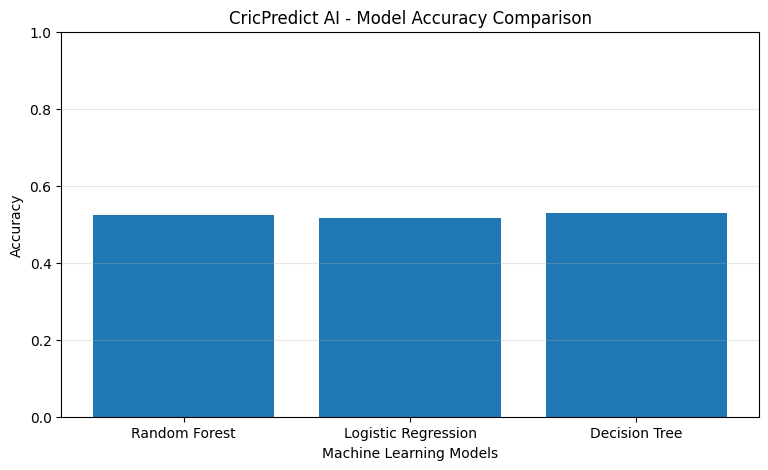

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("CricPredict AI - Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.grid(axis='y', alpha=0.3)
plt.show()

In [64]:
# ==========================================
# STEP 15: SAVE TRAINED MODELS
# ==========================================

import joblib
import os

# Create project folder
os.makedirs("CricPredict_AI", exist_ok=True)

# Save all three models
joblib.dump(
    rf_model,
    "CricPredict_AI/random_forest.pkl"
)

joblib.dump(
    lr_model,
    "CricPredict_AI/logistic_regression.pkl"
)

joblib.dump(
    dt_model,
    "CricPredict_AI/decision_tree.pkl"
)

# Save encoder
joblib.dump(
    encoder,
    "CricPredict_AI/encoder.pkl"
)

# Save feature columns
joblib.dump(
    list(X_train.columns),
    "CricPredict_AI/feature_columns.pkl"
)

print("ALL MODELS SAVED SUCCESSFULLY!")
print(os.listdir("CricPredict_AI"))

ALL MODELS SAVED SUCCESSFULLY!
['random_forest.pkl', 'logistic_regression.pkl', 'feature_columns.pkl', 'decision_tree.pkl', 'encoder.pkl']


In [65]:
import shutil

shutil.make_archive(
    "CricPredict_AI_Models",
    "zip",
    "CricPredict_AI"
)

from google.colab import files

files.download("CricPredict_AI_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>